# CHE1147 Group 6 — Tox21 Exploratory Data Analysis

This notebook **replaces the original Section 1** and keeps the proposal-focused analyses from the original **Section 2**, with an updated project layout and a new **label co-occurrence analysis**.

**Run cells from top to bottom.** The notebook begins with the **raw SDF** (`data/raw/tox21_10k_data_all.sdf`), converts it to a CSV (`data/processed/tox21_10k_data_all.csv`), canonicalizes and deduplicates structures, computes RDKit descriptors, performs EDA, then exports `data/processed/tox21_clean.csv` for modeling.

Project layout (this notebook lives in `src/`):

```text
CHE1147-Group-6/
├── data/
│   ├── raw/tox21_10k_data_all.sdf
│   └── processed/
├── notbooks/
│   ├── 01_EDA.ipynb
│   ├── 02_Preprocessing_Models_Evaluation.ipynb
│   └── 03_Results_Interpretation.ipynb
├── results/
│   ├── figures/
│   │   ├── EDA/
│   │   ├── Preprocessing_Models_Evaluation/
│   │   └── Results_Interpretation/
│   ├── metrics/
│   │   ├── EDA/
│   │   ├── Preprocessing_Models_Evaluation/
│   │   └── Results_Interpretation/
│   └── models/
│       ├── EDA/
│       ├── Preprocessing_Models_Evaluation/
│       └── Results_Interpretation/
├── README.md
├── pyproject.toml
└── uv.lock
```

**Scope:** descriptive analysis only. Missing/non-finite descriptors, constant features, and correlated features are **identified, not filtered for modeling**. The model notebook must fit all data-driven preprocessing/feature selection on its training sets and CV folds to avoid leakage.

**Duplicate policy retained from the proposal:** canonicalize isomeric SMILES and keep the first occurrence of each structure. This is provisional because discarded duplicate rows may have complementary or conflicting assay labels. Audit the diagnostics before final model training.

## 2.0 — Import libraries, locate repository, convert SDF → CSV

The raw SDF is the source of truth. This conversion deliberately runs before reading the CSV; it replaces the intermediate CSV from the raw SDF each time you execute this cell. Project-root detection works whether your notebook runs with the repository root or `src/` as its current working directory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import Descriptors, PandasTools
from IPython.display import display

# Find repository root regardless of whether Jupyter starts in src/ or the root.
s2_project_root = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / 'data' / 'raw' / 'tox21_10k_data_all.sdf').is_file()),
    None,
)
if s2_project_root is None:
    raise FileNotFoundError(
        'Cannot find data/raw/tox21_10k_data_all.sdf. '
        'Open this notebook inside the CHE1147-Group-6 repository, '
        'and check the SDF is in data/raw/.'
    )

s2_sdf = s2_project_root / 'data' / 'raw' / 'tox21_10k_data_all.sdf'
s2_processed = s2_project_root / 'data' / 'processed'
s2_figures = s2_project_root / 'results' / 'figures' / 'EDA'
s2_metrics = s2_project_root / 'results' / 'metrics' / 'EDA'

s2_processed.mkdir(parents=True, exist_ok=True)
for output_type in ('figures', 'metrics', 'models'):
    for stage in ('EDA', 'Preprocessing_Models_Evaluation', 'Results_Interpretation'):
        (s2_project_root / 'results' / output_type / stage).mkdir(
            parents=True, exist_ok=True
        )

s2_assays = ['SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']

# Step 1: Convert RAW SDF to an intermediate CSV, including molecule properties.
# No RDKit molecule object is written into the CSV.
s2_from_sdf = PandasTools.LoadSDF(
    str(s2_sdf),
    idName='ID',
    smilesName='SMILES',
    molColName=None,
    includeFingerprints=False,
)
s2_input_csv = s2_processed / 'tox21_10k_data_all.csv'
s2_from_sdf.to_csv(s2_input_csv, index=False)

# Step 2: Read the CSV generated in Step 1.
s2_raw = pd.read_csv(s2_input_csv)
s2_required = ['SMILES', *s2_assays]
s2_missing_columns = [col for col in s2_required if col not in s2_raw.columns]
if s2_missing_columns:
    raise ValueError(f'Missing columns after SDF conversion: {s2_missing_columns}')

print('Repository root:', s2_project_root)
print('SDF source:', s2_sdf.relative_to(s2_project_root))
print('Converted CSV:', s2_input_csv.relative_to(s2_project_root))
print(f'Converted records: {len(s2_raw):,}')
print(f'Available RDKit descriptors: {len(Descriptors._descList)}')
display(s2_raw[['SMILES', *s2_assays]].head())

[11:44:40] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[11:44:40] ERROR: Could not sanitize molecule ending on line 21572
[11:44:40] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[11:44:40] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[11:44:40] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[11:44:40] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[11:44:40] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[11:44:40] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[11:44:40] ERROR: Could not sanitize molecule ending on line 446665
[11:44:40] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[11:44:40] Explicit valence for atom # 1 Cl, 1, is greater than permitted
[11:44:40] ERROR: Could not sanitize molecule ending on l

Repository root: /Users/weikun/Desktop/PhD/CHE1147-Group-6
SDF source: data/raw/tox21_10k_data_all.sdf
Converted CSV: data/processed/tox21_10k_data_all.csv
Converted records: 11,761
Available RDKit descriptors: 217


,SMILES,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
0,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,NaN,NaN,0.0,NaN,NaN
1,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,NaN,NaN,0.0,NaN,NaN
2,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,NaN,NaN,0.0,NaN,NaN
3,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,NaN,NaN,1.0,NaN,NaN
4,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,NaN,NaN,NaN,NaN,NaN


## 2.1 — Label analysis: canonical structures, duplicates, missing labels and class balance

Record counts describe the newly converted SDF dataset. We use the deduplicated dataset for descriptor and assay analysis. Keep-first deduplication follows the proposal, but we explicitly check for conflicting labels before final modeling.

In [2]:
# SECTION 2.1A — Convert SMILES to canonical isomeric SMILES and keep FIRST duplicate.
# No attempt to merge repeated labels: this is deliberately provisional.
def s2_parse_canonical(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return None
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol, isomericSmiles=True) if mol is not None else None

s2_raw = s2_raw.copy()
s2_raw['s2_canonical_smiles'] = s2_raw['SMILES'].map(s2_parse_canonical)
s2_usable_raw = s2_raw.dropna(subset=['s2_canonical_smiles']).copy()
s2_unique = (
    s2_usable_raw.drop_duplicates(subset='s2_canonical_smiles', keep='first')
    .reset_index(drop=True).copy()
)

s2_raw_n = len(s2_raw)
s2_invalid = s2_raw_n - len(s2_usable_raw)
s2_dup_rows = len(s2_usable_raw) - len(s2_unique)
print(f'Original records: {s2_raw_n:,}')
print(f'Rows with invalid/missing canonical SMILES: {s2_invalid:,}')
print(f'Extra duplicate-structure rows removed (keep first): {s2_dup_rows:,}')
print(f'Unique canonical structures retained: {len(s2_unique):,}')

# Optional diagnostic: count structures with conflicting observed 0/1 labels,
# without changing how duplicates are handled.
s2_conflict_counts = (
    s2_usable_raw.groupby('s2_canonical_smiles')[s2_assays]
    .nunique(dropna=True).gt(1).sum()
)
print('Canonical structures with conflicting nonmissing labels (by assay):')
print(s2_conflict_counts.to_string())

s2_dataset_counts = pd.DataFrame([{
    'original_records': s2_raw_n,
    'distinct_original_smiles': s2_raw['SMILES'].nunique(dropna=True),
    'invalid_or_missing_canonical_smiles_rows': s2_invalid,
    'extra_duplicate_canonical_structure_rows': s2_dup_rows,
    'retained_unique_canonical_structures': len(s2_unique)
}])
s2_dataset_counts.to_csv(s2_metrics / 'eda_dataset_and_duplicates.csv', index=False)

Original records: 11,761
Rows with invalid/missing canonical SMILES: 0
Extra duplicate-structure rows removed (keep first): 3,720
Unique canonical structures retained: 8,041
Canonical structures with conflicting nonmissing labels (by assay):
SR-ARE      50
SR-ATAD5    24
SR-HSE      42
SR-MMP      35
SR-p53      20


[11:44:44] WARNING: not removing hydrogen atom without neighbors


In [3]:
# SECTION 2.1B — Counts and percentages per assay for ORIGINAL and UNIQUE records.
def s2_summarize_labels(frame):
    labels = frame[s2_assays].apply(pd.to_numeric, errors='coerce')
    # Valid assay classes are 0/1; leave all other values as untested/invalid.
    labels = labels.where(labels.isin([0, 1]))
    n_total = len(labels)
    table = pd.DataFrame(index=s2_assays)
    table.index.name = 'Assay'
    table['Total'] = n_total
    table['Labeled'] = labels.notna().sum()
    table['Missing'] = labels.isna().sum()
    table['Missing (%)'] = (100 * table['Missing'] / n_total).round(1)
    table['Inactive'] = labels.eq(0).sum()
    table['Active'] = labels.eq(1).sum()
    table['Active of labeled (%)'] = (
        100 * table['Active'] / table['Labeled'].replace(0, np.nan)
    ).round(1)
    return table

s2_label_original = s2_summarize_labels(s2_raw)
s2_label_unique = s2_summarize_labels(s2_unique)
s2_label_original.to_csv(s2_metrics / 'eda_labels_original_records.csv')
s2_label_unique.to_csv(s2_metrics / 'eda_labels_deduplicated.csv')
print('Original-record label composition:')
display(s2_label_original)
print('Deduplicated label composition:')
display(s2_label_unique)

Original-record label composition:


,Total,Labeled,Missing,Missing (%),Inactive,Active,Active of labeled (%)
Assay,,,,,,,
SR-ARE,11761,7166,4595,39.1,6069,1097,15.3
SR-ATAD5,11761,9089,2672,22.7,8751,338,3.7
SR-HSE,11761,8148,3613,30.7,7720,428,5.3
SR-MMP,11761,7319,4442,37.8,6177,1142,15.6
SR-p53,11761,8632,3129,26.6,8095,537,6.2


Deduplicated label composition:


,Total,Labeled,Missing,Missing (%),Inactive,Active,Active of labeled (%)
Assay,,,,,,,
SR-ARE,8041,5611,2430,30.2,4764,847,15.1
SR-ATAD5,8041,5551,2490,31.0,5364,187,3.4
SR-HSE,8041,6408,1633,20.3,6082,326,5.1
SR-MMP,8041,4419,3622,45.0,3737,682,15.4
SR-p53,8041,5227,2814,35.0,4946,281,5.4


### 2.1C — Label co-occurrence across the five stress-response assays (new)

**Professor's feedback:** Determine whether compounds active in one assay also tend to be active in other assays.

For each assay pair, use **only compounds with observed binary labels in both assays**. Report the number with jointly available labels, the four outcomes (00, 01, 10, 11), and:

- **Both-active rate:** percentage of pairwise labeled compounds active in **both** assays; a direct co-occurrence frequency.
- **Phi coefficient:** Pearson correlation of the paired 0/1 labels; helps assess association beyond simply counting rare positive labels.

The two heatmaps answer different questions. The both-active heatmap measures *frequency*; phi measures *association*. Neither establishes a shared causal biological mechanism. Missing labels are not treated as inactive.

In [4]:
# Prepare one shared five-assay label matrix; do not replace missing labels with zero.
s2_Y = s2_unique[s2_assays].apply(pd.to_numeric, errors='coerce')
s2_Y = s2_Y.where(s2_Y.isin([0, 1]))

s2_phi = pd.DataFrame(np.nan, index=s2_assays, columns=s2_assays)
s2_coactive_pct = pd.DataFrame(np.nan, index=s2_assays, columns=s2_assays)
s2_pairwise_n = pd.DataFrame(0, index=s2_assays, columns=s2_assays, dtype=int)
s2_cooc_rows = []

for i, assay_a in enumerate(s2_assays):
    for j, assay_b in enumerate(s2_assays):
        if i == j:
            observed = s2_Y[assay_a].dropna()
            s2_pairwise_n.loc[assay_a, assay_b] = len(observed)
            s2_coactive_pct.loc[assay_a, assay_b] = 100 * observed.eq(1).mean() if len(observed) else np.nan
            s2_phi.loc[assay_a, assay_b] = 1.0 if observed.nunique() == 2 else np.nan
            continue

        pair = s2_Y[[assay_a, assay_b]].dropna()
        n = len(pair)
        s2_pairwise_n.loc[assay_a, assay_b] = n
        if not n:
            continue

        both_active = int(((pair[assay_a] == 1) & (pair[assay_b] == 1)).sum())
        s2_coactive_pct.loc[assay_a, assay_b] = 100 * both_active / n
        if pair[assay_a].nunique() == 2 and pair[assay_b].nunique() == 2:
            s2_phi.loc[assay_a, assay_b] = pair[assay_a].corr(pair[assay_b])

        # Store each unordered assay pair once, with interpretable 2x2 counts.
        if i < j:
            n11 = both_active
            n10 = int(((pair[assay_a] == 1) & (pair[assay_b] == 0)).sum())
            n01 = int(((pair[assay_a] == 0) & (pair[assay_b] == 1)).sum())
            n00 = int(((pair[assay_a] == 0) & (pair[assay_b] == 0)).sum())
            pa = (n11 + n10) / n
            pb = (n11 + n01) / n
            s2_cooc_rows.append({
                'Assay_A': assay_a,
                'Assay_B': assay_b,
                'Jointly_labeled_n': n,
                'both_inactive_00': n00,
                'A_inactive_B_active_01': n01,
                'A_active_B_inactive_10': n10,
                'both_active_11': n11,
                'A_active_pct': 100 * pa,
                'B_active_pct': 100 * pb,
                'both_active_pct': 100 * n11 / n,
                'expected_both_active_pct_if_independent': 100 * pa * pb,
                'phi': s2_phi.loc[assay_a, assay_b],
            })

s2_cooc_table = pd.DataFrame(s2_cooc_rows)
s2_cooc_table.to_csv(s2_metrics / 'eda_assay_cooccurrence_pairs.csv', index=False)
s2_phi.to_csv(s2_metrics / 'eda_assay_phi_correlation.csv', index_label='Assay')
s2_pairwise_n.to_csv(s2_metrics / 'eda_assay_pairwise_label_counts.csv', index_label='Assay')
s2_coactive_pct.to_csv(s2_metrics / 'eda_assay_both_active_pct.csv', index_label='Assay')

print('Pairwise co-occurrence results (each pair counted once):')
display(s2_cooc_table.round(3))
print('Phi correlation matrix:')
display(s2_phi.round(3))
print('Number of compounds observed in both assays:')
display(s2_pairwise_n)

Pairwise co-occurrence results (each pair counted once):


,Assay_A,Assay_B,Jointly_labeled_n,both_inactive_00,A_inactive_B_active_01,A_active_B_inactive_10,both_active_11,A_active_pct,B_active_pct,both_active_pct,expected_both_active_pct_if_independent,phi
0,SR-ARE,SR-ATAD5,3732,3184,24,457,67,14.041,2.438,1.795,0.342,0.271
1,SR-ARE,SR-HSE,5277,4528,64,572,113,12.981,3.354,2.141,0.435,0.282
2,SR-ARE,SR-MMP,2969,2465,118,190,196,13.001,10.576,6.602,1.375,0.505
3,SR-ARE,SR-p53,3583,3134,26,348,75,11.806,2.819,2.093,0.333,0.330
4,SR-ATAD5,SR-HSE,4167,3897,158,81,31,2.688,4.536,0.744,0.122,0.185
5,SR-ATAD5,SR-MMP,4246,3659,492,42,53,2.237,12.836,1.248,0.287,0.194
6,SR-ATAD5,SR-p53,5097,4804,156,75,62,2.688,4.277,1.216,0.115,0.337
7,SR-HSE,SR-MMP,3284,2820,321,70,73,4.354,11.998,2.223,0.522,0.256
8,SR-HSE,SR-p53,4023,3802,68,92,61,3.803,3.207,1.516,0.122,0.414
9,SR-MMP,SR-p53,4056,3584,63,314,95,10.084,3.895,2.342,0.393,0.335


Phi correlation matrix:


,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
SR-ARE,1.000,0.271,0.282,0.505,0.330
SR-ATAD5,0.271,1.000,0.185,0.194,0.337
SR-HSE,0.282,0.185,1.000,0.256,0.414
SR-MMP,0.505,0.194,0.256,1.000,0.335
SR-p53,0.330,0.337,0.414,0.335,1.000


Number of compounds observed in both assays:


,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
SR-ARE,5611,3732,5277,2969,3583
SR-ATAD5,3732,5551,4167,4246,5097
SR-HSE,5277,4167,6408,3284,4023
SR-MMP,2969,4246,3284,4419,4056
SR-p53,3583,5097,4023,4056,5227


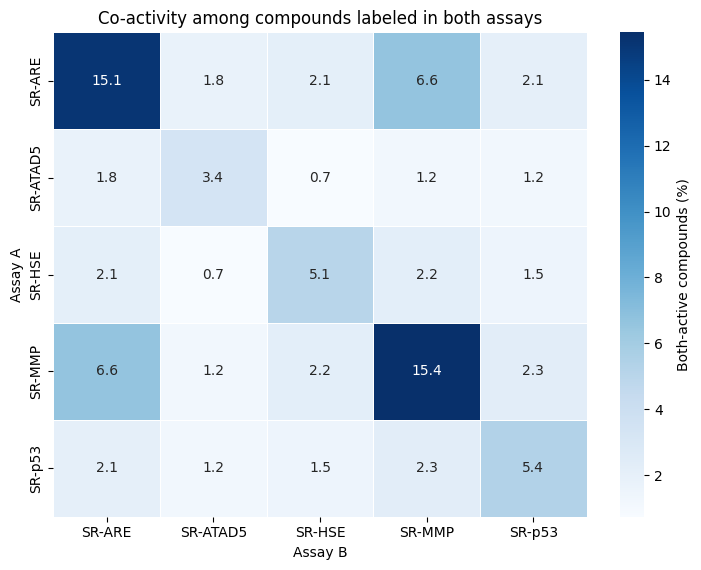

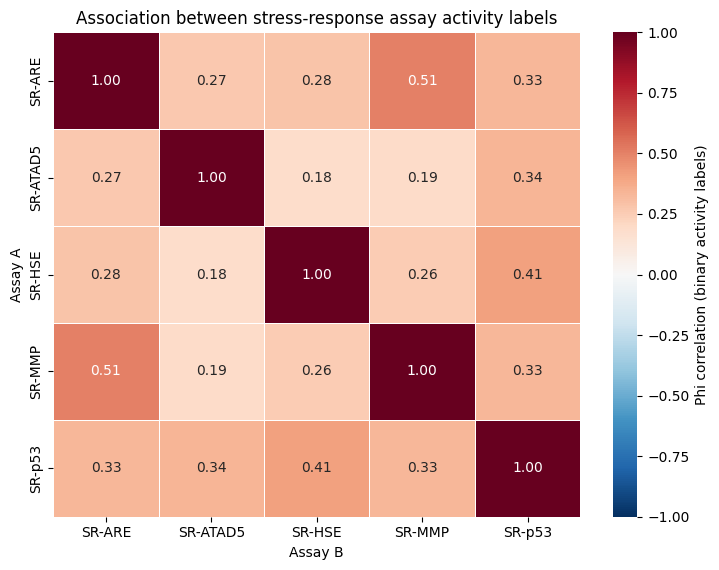

Caution: pairwise-labeled sample sizes differ. See eda_assay_pairwise_label_counts.csv.


In [5]:
# Heatmap 1: observed percent active in BOTH assays (pairwise-labeled denominator).
fig, ax = plt.subplots(figsize=(7.4, 5.8))
sns.heatmap(
    s2_coactive_pct, annot=True, fmt='.1f', cmap='Blues',
    linewidths=0.5, cbar_kws={'label': 'Both-active compounds (%)'}, ax=ax,
)
ax.set_title('Co-activity among compounds labeled in both assays')
ax.set_xlabel('Assay B')
ax.set_ylabel('Assay A')
fig.tight_layout()
fig.savefig(s2_figures / 'figure3_assay_coactivity_pct.png', dpi=300, bbox_inches='tight')
plt.show()

# Heatmap 2: phi association between labels, using only jointly observed pairs.
fig, ax = plt.subplots(figsize=(7.4, 5.8))
sns.heatmap(
    s2_phi, annot=True, fmt='.2f', cmap='RdBu_r',
    vmin=-1, vmax=1, center=0, linewidths=0.5,
    cbar_kws={'label': 'Phi correlation (binary activity labels)'}, ax=ax,
)
ax.set_title('Association between stress-response assay activity labels')
ax.set_xlabel('Assay B')
ax.set_ylabel('Assay A')
fig.tight_layout()
fig.savefig(s2_figures / 'figure4_assay_phi_correlation.png', dpi=300, bbox_inches='tight')
plt.show()

print('Caution: pairwise-labeled sample sizes differ. See eda_assay_pairwise_label_counts.csv.')

### 2.1D — Multi-assay activity breadth: how many of the five assays are active? (new)

The pairwise analysis in **2.1C** identifies *which two* assays tend to be co-active. This complementary analysis counts **0, 1, 2, 3, 4, or 5 active assays for each compound** and asks, for a compound active in a particular assay, how many of the *other four* assays are also active.

**Missing-label rule:** Use **complete cases only** (compounds with measured 0/1 labels in all five assays). Otherwise, a compound with two positive labels and three missing labels could be incorrectly labeled as exactly two-out-of-five. We report the number and fraction of complete cases. Pairwise Section 2.1C still uses all available *jointly labeled pairs*, which may include more compounds.

**Two complementary plots:** (1) distribution of the number of active assays among completely labeled compounds; (2) conditional distribution of *total* active assays (1–5), among completely labeled compounds active in each specific assay. These are descriptive statistics, not evidence of a causal effect.


Compounds with all five assay labels: 2,683 / 8,041 (33.4% of deduplicated compounds)


,active_assay_count,compound_count,percentage_of_complete_cases
0,0,2314,86.25
1,1,265,9.88
2,2,65,2.42
3,3,33,1.23
4,4,5,0.19
5,5,1,0.04


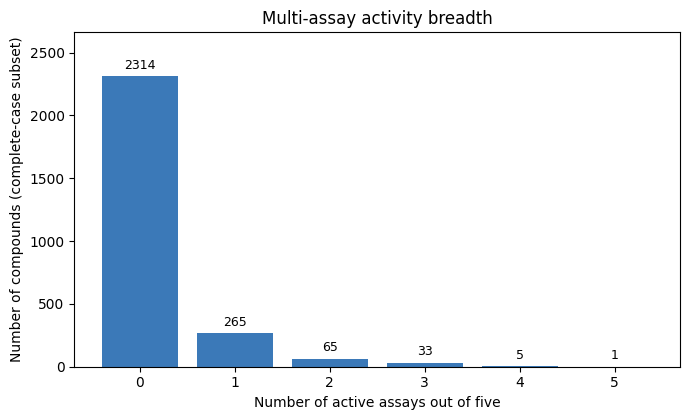

Given that the row assay is active, how many assays are active in total? (%)


,1,2,3,4,5
SR-ARE,57.9,25.4,14.0,2.2,0.4
SR-ATAD5,21.9,6.2,56.2,12.5,3.1
SR-HSE,64.3,17.9,10.7,5.4,1.8
SR-MMP,48.2,32.7,16.7,1.8,0.6
SR-p53,25.7,14.3,42.9,14.3,2.9


Positive compounds in each row assay, restricted to complete cases:


,active_anchor_n
SR-ARE,228.0
SR-ATAD5,32.0
SR-HSE,56.0
SR-MMP,168.0
SR-p53,35.0


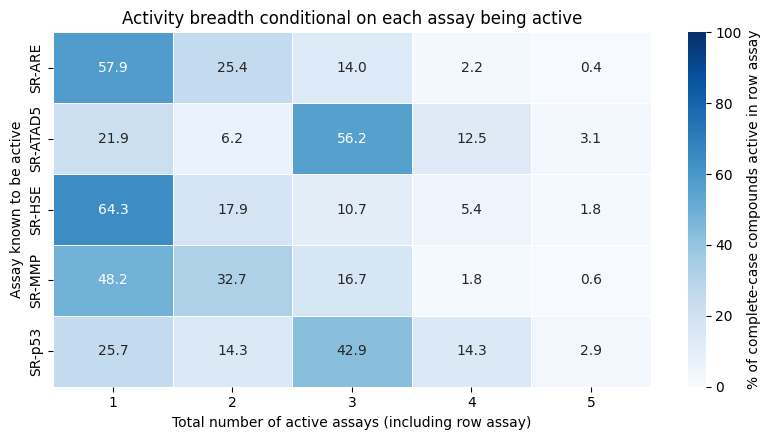

In [6]:
# SECTION 2.1D — Complete-case multi-assay response breadth.
# Every row represents one unique canonical compound; labels are 0, 1, or NaN.
s2_complete5 = s2_Y.dropna(subset=s2_assays).copy()
s2_n_all = len(s2_Y)
s2_n_complete5 = len(s2_complete5)
s2_complete_fraction = 100 * s2_n_complete5 / s2_n_all if s2_n_all else np.nan
print(f'Compounds with all five assay labels: {s2_n_complete5:,} / {s2_n_all:,} '
      f'({s2_complete_fraction:.1f}% of deduplicated compounds)')

if s2_n_complete5 == 0:
    print('No complete five-assay cases. Cannot interpret exact 0–5 activity breadth.')
else:
    # Number of active endpoints out of exactly five, including zero.
    s2_num_active5 = s2_complete5.sum(axis=1).astype(int)
    s2_active5_counts = s2_num_active5.value_counts().reindex(range(6), fill_value=0)
    s2_breadth_table = pd.DataFrame({
        'active_assay_count': list(range(6)),
        'compound_count': s2_active5_counts.values,
        'percentage_of_complete_cases': (100 * s2_active5_counts / s2_n_complete5).values,
    })
    s2_breadth_table.to_csv(
        s2_metrics / 'eda_multiassay_activity_breadth.csv', index=False
    )
    display(s2_breadth_table.round(2))

    fig, ax = plt.subplots(figsize=(7, 4.3))
    bars = ax.bar(s2_breadth_table['active_assay_count'],
                  s2_breadth_table['compound_count'], color='#3B79B8')
    ax.set_xticks(list(range(6)))
    ax.set_xlabel('Number of active assays out of five')
    ax.set_ylabel('Number of compounds (complete-case subset)')
    ax.set_title('Multi-assay activity breadth')
    ax.bar_label(bars, padding=3, fontsize=9)
    ax.set_ylim(0, max(1, s2_active5_counts.max() * 1.15))
    fig.tight_layout()
    fig.savefig(s2_figures / 'eda_multiassay_activity_breadth.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Anchor assay analysis: if an endpoint is active, how many endpoints total
    # (including the anchor) are active among compounds measured on all five?
    s2_anchor_breadth_pct = pd.DataFrame(index=s2_assays, columns=range(1, 6), dtype=float)
    s2_anchor_breadth_n = pd.DataFrame(0, index=s2_assays, columns=range(1, 6), dtype=int)
    s2_anchor_positive_n = pd.Series(index=s2_assays, dtype=int, name='active_anchor_n')
    for s2_assay in s2_assays:
        s2_anchor_mask = s2_complete5[s2_assay].eq(1)
        s2_anchor_counts = s2_num_active5.loc[s2_anchor_mask].value_counts().reindex(
            range(1, 6), fill_value=0
        )
        s2_anchor_n = int(s2_anchor_mask.sum())
        s2_anchor_positive_n.loc[s2_assay] = s2_anchor_n
        s2_anchor_breadth_n.loc[s2_assay, :] = s2_anchor_counts.values
        if s2_anchor_n:
            s2_anchor_breadth_pct.loc[s2_assay, :] = 100 * s2_anchor_counts.values / s2_anchor_n

    s2_anchor_breadth_n.to_csv(
        s2_metrics / 'eda_anchor_assay_activity_breadth_counts.csv', index_label='Assay'
    )
    s2_anchor_breadth_pct.to_csv(
        s2_metrics / 'eda_anchor_assay_activity_breadth_pct.csv', index_label='Assay'
    )
    print('Given that the row assay is active, how many assays are active in total? (%)')
    display(s2_anchor_breadth_pct.round(1))
    print('Positive compounds in each row assay, restricted to complete cases:')
    display(s2_anchor_positive_n.to_frame())

    if s2_anchor_positive_n.gt(0).any():
        fig, ax = plt.subplots(figsize=(8.2, 4.5))
        sns.heatmap(s2_anchor_breadth_pct, annot=True, fmt='.1f', cmap='Blues',
                    vmin=0, vmax=100, linewidths=0.5,
                    cbar_kws={'label': '% of complete-case compounds active in row assay'},
                    ax=ax)
        ax.set_xlabel('Total number of active assays (including row assay)')
        ax.set_ylabel('Assay known to be active')
        ax.set_title('Activity breadth conditional on each assay being active')
        fig.tight_layout()
        fig.savefig(s2_figures / 'eda_anchor_assay_activity_breadth.png',
                    dpi=300, bbox_inches='tight')
        plt.show()


## 2.2 — Molecular descriptor analysis (X)

Assess **all available RDKit descriptors** for non-finite values, missingness, variance, and redundancy. Create four representative descriptor distribution plots with IQR fences for continuous descriptors. These are diagnostics, **not preprocessing decisions for the final models**.

In [7]:
# SECTION 2.2A — Compute all RDKit descriptors ONCE per unique canonical structure.
# No reliance on teammate's previous shortened 51-feature dataframe.
s2_descriptor_names = [name for name, fn in Descriptors._descList]

def s2_describe_structure(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return {name: np.nan for name in s2_descriptor_names}
    try:
        return Descriptors.CalcMolDescriptors(mol, missingVal=np.nan, silent=True)
    except Exception:
        return {name: np.nan for name in s2_descriptor_names}

s2_descriptor_records = [
    s2_describe_structure(s) for s in s2_unique['s2_canonical_smiles']
]
s2_X = pd.DataFrame(s2_descriptor_records, columns=s2_descriptor_names)
s2_X = s2_X.apply(pd.to_numeric, errors='coerce')
s2_X = s2_X.replace([np.inf, -np.inf], np.nan)
s2_Y = s2_unique[s2_assays].apply(pd.to_numeric, errors='coerce')
s2_Y = s2_Y.where(s2_Y.isin([0, 1]))

assert len(s2_X) == len(s2_unique) == len(s2_Y)
assert s2_X.index.equals(s2_Y.index)
print(f'Molecules with descriptors: {len(s2_X):,}')
print(f'Descriptor columns: {s2_X.shape[1]:,}')
print(f'Descriptor entries: {s2_X.size:,}')

[11:45:23] WARNING: not removing hydrogen atom without neighbors
[11:45:23] WARNING: not removing hydrogen atom without neighbors


Molecules with descriptors: 8,041
Descriptor columns: 217
Descriptor entries: 1,744,897


In [8]:
# SECTION 2.2B — Missing/non-finite values, constant features, ALL-descriptor summary stats.
s2_missing_by_feature = s2_X.isna().sum()
s2_nunique = s2_X.nunique(dropna=True)
s2_constant = s2_nunique[s2_nunique == 1].index.tolist()
s2_allmissing = s2_nunique[s2_nunique == 0].index.tolist()
s2_missing_total = int(s2_missing_by_feature.sum())
s2_missing_percent = 100 * s2_missing_total / s2_X.size if s2_X.size else np.nan

s2_quality = pd.DataFrame({
    'missing_or_nonfinite_n': s2_missing_by_feature,
    'missing_or_nonfinite_pct': (100 * s2_missing_by_feature / len(s2_X)).round(3),
    'distinct_nonmissing_values': s2_nunique,
    'constant': s2_nunique.eq(1),
    'all_missing': s2_nunique.eq(0),
})
s2_quality.to_csv(s2_metrics / 'all_descriptor_quality.csv', index_label='Descriptor')

s2_all_stats = s2_X.describe(percentiles=[.25, .5, .75]).T
s2_all_stats['IQR'] = s2_all_stats['75%'] - s2_all_stats['25%']
s2_all_stats['skewness'] = s2_X.skew()
s2_all_stats.to_csv(s2_metrics / 'all_descriptor_descriptive_statistics.csv', index_label='Descriptor')

print(f'Descriptors with >=1 missing/non-finite entry: {(s2_missing_by_feature > 0).sum():,}')
print(f'Total missing/non-finite descriptor entries: {s2_missing_total:,} ({s2_missing_percent:.3f}%)')
print(f'Constant descriptors (exactly one observed value): {len(s2_constant)}', s2_constant)
print(f'All-missing descriptors: {len(s2_allmissing)}', s2_allmissing)
print('10 most affected descriptors:')
display(s2_quality.sort_values('missing_or_nonfinite_n', ascending=False).head(10))

# For Pearson correlations only, skip descriptors with no variation.
# We have not deleted these columns from s2_X or s2_all_stats.
s2_usable_features = s2_nunique[s2_nunique > 1].index.tolist()

Descriptors with >=1 missing/non-finite entry: 12
Total missing/non-finite descriptor entries: 4,662 (0.267%)
Constant descriptors (exactly one observed value): 3 ['SMR_VSA8', 'SlogP_VSA9', 'fr_diazo']
All-missing descriptors: 0 []
10 most affected descriptors:


,missing_or_nonfinite_n,missing_or_nonfinite_pct,distinct_nonmissing_values,constant,all_missing
BCUT2D_MWHI,530,6.591,7402,False,False
BCUT2D_LOGPHI,530,6.591,7370,False,False
BCUT2D_CHGHI,530,6.591,7370,False,False
BCUT2D_MWLOW,530,6.591,7391,False,False
BCUT2D_LOGPLOW,530,6.591,7364,False,False
BCUT2D_MRHI,530,6.591,7370,False,False
BCUT2D_MRLOW,530,6.591,7360,False,False
BCUT2D_CHGLO,530,6.591,7368,False,False
MaxAbsPartialCharge,106,1.318,6474,False,False
MaxPartialCharge,106,1.318,6735,False,False


In [9]:
# SECTION 2.2C — ALL-feature Pearson redundancy check (without dropping features).
s2_xx_corr = s2_X[s2_usable_features].corr(method='pearson')
s2_upper = s2_xx_corr.where(
    np.triu(np.ones(s2_xx_corr.shape, dtype=bool), k=1)
)
s2_strong_pairs = (
    s2_upper.stack().loc[lambda r: r.abs() > 0.90]
    .rename('Pearson_r')
    .reset_index()
)
s2_strong_pairs.columns = ['Descriptor_1', 'Descriptor_2', 'Pearson_r']
s2_strong_pairs['abs_r'] = s2_strong_pairs['Pearson_r'].abs()
s2_strong_pairs = s2_strong_pairs.sort_values('abs_r', ascending=False)
s2_strong_pairs.to_csv(s2_metrics / 'descriptor_pairs_abs_r_gt_0p90.csv', index=False)

print(f'Usable nonconstant descriptors for correlations: {len(s2_usable_features):,}')
print(f'Descriptor pairs with |Pearson r| > 0.90: {len(s2_strong_pairs):,}')
print('10 strongest redundant pairs:')
display(s2_strong_pairs.head(10))

Usable nonconstant descriptors for correlations: 214
Descriptor pairs with |Pearson r| > 0.90: 143
10 strongest redundant pairs:


,Descriptor_1,Descriptor_2,Pearson_r,abs_r
136,fr_Ar_NH,fr_Nhpyrrole,1.000000,1.000000
131,NumAmideBonds,fr_amide,1.000000,1.000000
2,MolWt,ExactMolWt,0.999995,0.999995
0,MaxAbsEStateIndex,MaxEStateIndex,0.999913,0.999913
117,Kappa2,Phi,0.999851,0.999851
1,MolWt,HeavyAtomMolWt,0.998629,0.998629
14,HeavyAtomMolWt,ExactMolWt,0.998570,0.998570
132,NumAromaticCarbocycles,fr_benzene,0.997820,0.997820
89,Chi1,HeavyAtomCount,0.997786,0.997786
139,fr_COO,fr_COO2,0.997157,0.997157


IQR outlier analysis (unique molecular structures):


,Valid_n,Q1,Q3,IQR,Lower_1p5_IQR,Upper_1p5_IQR,Potential_outliers_n,Potential_outliers_pct
Descriptor,,,,,,,,
MolWt,8041,169.180,355.387,186.207,-110.131,634.698,303,3.768
MolLogP,8041,0.919,3.568,2.649,-3.054,7.540,384,4.776
TPSA,8041,26.300,80.260,53.960,-54.640,161.200,423,5.261


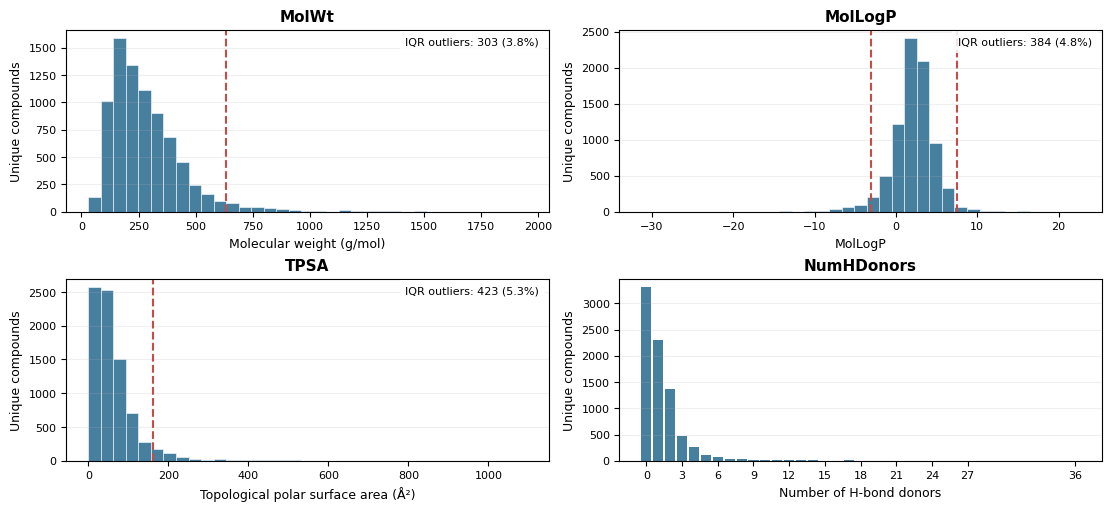

Selected descriptor descriptive statistics:


,count,mean,std,min,25%,50%,75%,max,IQR,skewness
MolWt,8041.0,285.315,172.293,30.026,169.180,247.276,355.387,1950.681,186.207,2.519
MolLogP,8041.0,2.105,2.677,-31.312,0.919,2.265,3.568,22.612,2.649,-1.244
TPSA,8041.0,62.241,63.772,0.000,26.300,47.580,80.260,1095.850,53.960,4.431
NumHDonors,8041.0,1.281,2.068,0.000,0.000,1.000,2.000,36.000,2.000,5.455


In [10]:
# SECTION 2.2D — FIGURE 1: 4 representative histograms; IQR fences for 3 continuous descriptors.
s2_display_features = ['MolWt', 'MolLogP', 'TPSA', 'NumHDonors']
s2_missing_plot_features = [f for f in s2_display_features if f not in s2_X.columns]
if s2_missing_plot_features:
    raise ValueError(f'RDKit descriptors not found: {s2_missing_plot_features}')

s2_outlier_rows = []
for feature in ['MolWt', 'MolLogP', 'TPSA']:
    vals = s2_X[feature].dropna()
    q1, q3 = vals.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    count = int(((vals < lower) | (vals > upper)).sum())
    s2_outlier_rows.append({
        'Descriptor': feature,
        'Valid_n': len(vals), 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'Lower_1p5_IQR': lower, 'Upper_1p5_IQR': upper,
        'Potential_outliers_n': count,
        'Potential_outliers_pct': 100*count/len(vals) if len(vals) else np.nan,
    })
s2_outlier_table = pd.DataFrame(s2_outlier_rows).set_index('Descriptor')
s2_outlier_table.to_csv(s2_metrics / 'table_1p5IQR_outliers_three_continuous.csv')
print('IQR outlier analysis (unique molecular structures):')
display(s2_outlier_table.round(3))

s2_titles = {
    'MolWt': 'Molecular weight (g/mol)',
    'MolLogP': 'MolLogP',
    'TPSA': 'Topological polar surface area (Å²)',
    'NumHDonors': 'Number of H-bond donors',
}
fig, axes = plt.subplots(2, 2, figsize=(11, 5), constrained_layout=True)
for ax, feature in zip(axes.flat, s2_display_features):
    vals = s2_X[feature].dropna()
    if feature == 'NumHDonors':
        counts = vals.astype(int).value_counts().sort_index()
        ax.bar(counts.index, counts.values, width=0.85, color='#477f9f')
        ax.set_xticks(counts.index[::max(1, int(np.ceil(len(counts)/12)))])
    else:
        ax.hist(vals, bins=35, color='#477f9f', edgecolor='white', linewidth=0.4)
        lower = s2_outlier_table.loc[feature, 'Lower_1p5_IQR']
        upper = s2_outlier_table.loc[feature, 'Upper_1p5_IQR']
        # The fences are computed regardless; plot a line only if it falls in the visible range.
        if vals.min() <= lower <= vals.max():
            ax.axvline(lower, color='#c64c47', linestyle='--', linewidth=1.5,
                       label='1.5×IQR fence')
        if vals.min() <= upper <= vals.max():
            ax.axvline(upper, color='#c64c47', linestyle='--', linewidth=1.5,
                       label='1.5×IQR fence')
        n = s2_outlier_table.loc[feature, 'Potential_outliers_n']
        p = s2_outlier_table.loc[feature, 'Potential_outliers_pct']
        ax.text(.98, .96, f'IQR outliers: {n:,} ({p:.1f}%)',
                transform=ax.transAxes, va='top', ha='right', fontsize=8,
                bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': .85})
    ax.set_title(feature, fontsize=11, fontweight='bold')
    ax.set_xlabel(s2_titles[feature], fontsize=9)
    ax.set_ylabel('Unique compounds', fontsize=9)
    ax.tick_params(labelsize=8)
    ax.grid(axis='y', alpha=.2)

#fig.suptitle('Figure 1. Molecular descriptor distributions and potential outliers', fontsize=12)
fig.savefig(s2_figures / 'figure1_descriptor_histograms.png', dpi=300, bbox_inches='tight')
plt.show()

print('Selected descriptor descriptive statistics:')
display(s2_all_stats.loc[s2_display_features,
    ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR', 'skewness']
].round(3))

## 2.3 — Descriptor–activity relationships (X–y)

Compute per-assay Pearson correlations for valid descriptor–label observations. Show the 20 descriptors with the largest maximum absolute correlation across the five endpoints. These features are selected **only for this EDA figure**; they must not be used as a test-informed feature-selection shortcut in Notebook 02.

Top-20 descriptors ranked by maximum |Pearson r| across five endpoints:


,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
fr_benzene,0.175,0.114,0.072,0.349,0.168
NumAromaticCarbocycles,0.175,0.115,0.071,0.348,0.169
NumAromaticRings,0.204,0.129,0.076,0.320,0.191
SMR_VSA7,0.195,0.111,0.084,0.320,0.149
SlogP_VSA6,0.191,0.112,0.087,0.290,0.125
VSA_EState6,0.142,0.103,0.064,0.283,0.111
MolLogP,0.141,0.039,0.112,0.273,0.067
BCUT2D_LOGPHI,0.158,0.050,0.076,0.272,0.154
fr_Ar_OH,0.130,0.081,0.065,0.259,0.123
fr_phenol,0.133,0.083,0.068,0.259,0.128


Largest observed absolute correlation in displayed set: 0.349


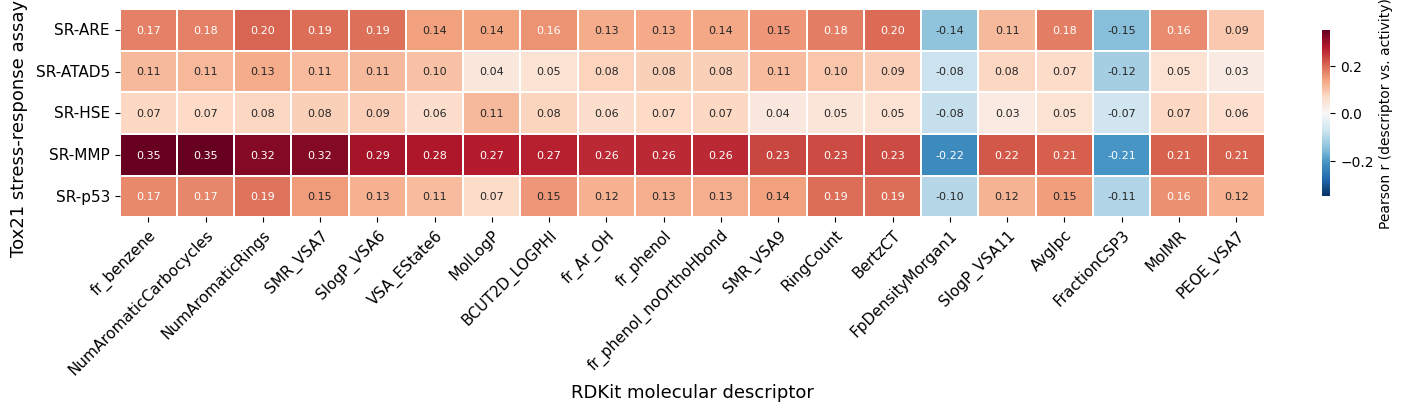

In [11]:
# SECTION 2.3 — Pearson correlations with all five endpoints, and FIGURE 2.
s2_xy_corr = pd.DataFrame(index=s2_usable_features)
s2_pair_counts = pd.DataFrame(index=s2_usable_features)
for assay in s2_assays:
    y = s2_Y[assay]
    x = s2_X[s2_usable_features]
    s2_xy_corr[assay] = x.corrwith(y, method='pearson')
    s2_pair_counts[assay] = x.notna().mul(y.notna(), axis=0).sum(axis=0)

s2_xy_corr.to_csv(s2_metrics / 'all_descriptor_endpoint_pearson_r.csv', index_label='Descriptor')
s2_pair_counts.to_csv(s2_metrics / 'all_descriptor_endpoint_valid_pair_counts.csv', index_label='Descriptor')

s2_top20_scores = s2_xy_corr.abs().max(axis=1).dropna().nlargest(20)
s2_top20 = s2_xy_corr.loc[s2_top20_scores.index]
s2_top20.to_csv(s2_metrics / 'figure2_top20_descriptor_endpoint_correlations.csv', index_label='Descriptor')
print('Top-20 descriptors ranked by maximum |Pearson r| across five endpoints:')
display(s2_top20.round(3))
print('Largest observed absolute correlation in displayed set:',
      round(float(s2_top20.abs().max().max()), 3) if not s2_top20.empty else 'none')

if s2_top20.empty:
    print('Cannot plot heatmap: no usable feature–label correlations were available.')
else:
    # Transpose: rows = 5 assays, columns = top 20 descriptors
    heatmap_data = s2_top20.T

    # Wider and shorter figure for the proposal
    fig, ax = plt.subplots(figsize=(14, 4), constrained_layout=True)

    # Symmetric colour scale centered at zero
    limit = max(0.05, float(np.nanmax(np.abs(heatmap_data.to_numpy()))))

    sns.heatmap(
        heatmap_data,
        ax=ax,
        cmap='RdBu_r',
        center=0,
        vmin=-limit,
        vmax=limit,
        linewidths=0.25,
        annot=True,
        fmt='.2f',
        annot_kws={'fontsize': 8},
        cbar_kws={
            'label': 'Pearson r (descriptor vs. activity)',
            'shrink': 0.8
        }
    )

    #ax.set_title(
    #    'Figure 2. Top-20 descriptor–endpoint correlations',
    #    fontsize=13,
    #    pad=10
    #)

    ax.set_xlabel('RDKit molecular descriptor', fontsize=13)
    ax.set_ylabel('Tox21 stress-response assay', fontsize=13)
    
    # Adjust y-axis label position
    ax.yaxis.set_label_coords(-0.08, 0.43)

    # Rotate descriptor labels for readability
    ax.tick_params(axis='x', labelrotation=45, labelsize=11)
    ax.tick_params(axis='y', labelrotation=0, labelsize=11)

    # Align rotated labels
    plt.setp(ax.get_xticklabels(), ha='right', rotation_mode='anchor')

    # Access the colorbar
    cbar = ax.collections[0].colorbar

    # Set colorbar tick label font size
    cbar.ax.tick_params(labelsize=10)

    # Set colorbar title/label font size
    cbar.set_label('Pearson r (descriptor vs. activity)', fontsize=10)

    # Save figure
    fig.savefig(
        s2_figures / 'figure2_top20_descriptor_endpoint_heatmap.png',
        dpi=300,
        bbox_inches='tight'
    )


    plt.show()

## 2.4 — Export cleaned dataset for model training and summarize outputs

Save **one row per retained canonical molecular structure** with the five original assay labels (missing labels preserved), canonical SMILES, molecule ID when available, and all computed RDKit descriptors (including missing values). Feature filtering, assay-specific dropping of unlabeled compounds, scaffold splits and scaling happen later in Notebook 02.

In [12]:
# Construct modeling-ready *input* (not yet feature-selected, split, or imputed).
s2_metadata_columns = [col for col in ['ID', 'SMILES'] if col in s2_unique.columns]
s2_export_metadata = s2_unique[s2_metadata_columns].copy()
s2_export_metadata['canonical_smiles'] = s2_unique['s2_canonical_smiles']
s2_clean = pd.concat(
    [s2_export_metadata.reset_index(drop=True),
     s2_Y.reset_index(drop=True),
     s2_X.reset_index(drop=True)],
    axis=1,
)
assert len(s2_clean) == len(s2_unique)
assert s2_clean['canonical_smiles'].is_unique
assert s2_clean.columns.is_unique
s2_clean_path = s2_processed / 'tox21_clean.csv'
s2_clean.to_csv(s2_clean_path, index=False)

s2_lines = [
    'CHE1147 — Tox21 EDA SUMMARY',
    '===========================',
    f'Raw SDF path: {s2_sdf.relative_to(s2_project_root)}',
    f'SDF-converted CSV: {s2_input_csv.relative_to(s2_project_root)}',
    f'Original records: {s2_raw_n:,}',
    f'Invalid or missing canonical structures: {s2_invalid:,}',
    f'Duplicate canonical structure rows removed (keep first): {s2_dup_rows:,}',
    f'Unique canonical structures retained: {len(s2_unique):,}',
    f'RDKit descriptors generated: {s2_X.shape[1]}',
    f'Descriptors with any missing/non-finite entries: {(s2_missing_by_feature > 0).sum()}',
    f'Missing/non-finite descriptor entries: {s2_missing_total:,} ({s2_missing_percent:.3f}%)',
    f'Constant descriptors: {len(s2_constant)} ({", ".join(s2_constant) or "none"})',
    f'Descriptor pairs with |Pearson r| > 0.90: {len(s2_strong_pairs)}',
    '', 'Label summary (deduplicated):',
    s2_label_unique.to_string(),
    '', 'Assay co-occurrence (jointly observed labels only):',
    s2_cooc_table.round(3).to_string(index=False),
    '', 'IQR outlier statistics:',
    s2_outlier_table.round(3).to_string(),
    '', 'Top 20 descriptor–endpoint correlations:',
    s2_top20.round(3).to_string(),
    '', 'NOTES:',
    '- Duplicate structures retain FIRST observation; reconcile before final ML if needed.',
    '- Missing assay labels remain missing and are filtered PER ASSAY in Notebook 02.',
    '- EDA descriptors are not used to fit global preprocessing or select ML features.',
]
s2_summary_path = s2_metrics / 'eda_summary_for_writeup.txt'
s2_summary_path.write_text('\n'.join(s2_lines), encoding='utf-8')

print('Model input saved:', s2_clean_path.relative_to(s2_project_root))
print('Shape:', s2_clean.shape)
print('Summary saved:', s2_summary_path.relative_to(s2_project_root))
print('Figures folder:', s2_figures.relative_to(s2_project_root))
print('Metrics folder:', s2_metrics.relative_to(s2_project_root))
display(s2_clean.head(3))

Model input saved: data/processed/tox21_clean.csv
Shape: (8041, 225)
Summary saved: results/metrics/EDA/eda_summary_for_writeup.txt
Figures folder: results/figures/EDA
Metrics folder: results/metrics/EDA


,ID,SMILES,canonical_smiles,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,MaxAbsEStateIndex,MaxEStateIndex,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,NaN,NaN,0.0,NaN,NaN,5.828705,5.828705,...,0,0,0,0,0,0,0,0,0,0
1,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,NaN,NaN,0.0,NaN,NaN,12.408729,12.408729,...,0,0,0,0,0,0,0,0,0,0
2,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,NaN,NaN,0.0,NaN,NaN,11.816299,11.816299,...,0,0,0,0,0,0,0,0,0,0
